# Trade: Cameron Boozer for Austin Reaves (2026-11-16)

Ligma Sugma (team 4) gives **Cameron Boozer** to Jons of Soe Ingles for **Austin Reaves**, 1-for-1.
Build: win **PTS, AST, STL, 3PM, FT%**; punt REB, BLK, FG%, TO.

The case for it, in four charts:

1. **Fit:** Boozer's value today sits in categories you punt; Reaves's sits in your targets.
2. **Weekly results:** the full-league simulation wins you more PTS, STL and FG% weeks.
3. **Season:** playoff odds rise by about 8 points under both projections, and the trade partner is a playoff rival.
4. **Cost:** Reaves is worth more every season through 2030; Boozer only catches up at the end of the 5-year window.

Engine: `analysis/trade_eval.py` (9-cat z-scores, aging curve, whole-league Monte Carlo with every team's best legal
lineup each day). Same settings as `python analysis/trade_eval.py --team 4 --give "Cameron Boozer" --get "Austin Reaves"
--targets PTS AST STL FG3M FT --avail "Stephen Curry=0.6" --sims 1000`.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'analysis'))
import trade_eval as te
from fbb.db import engine

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
SEASON, ME = 2027, 4
TARGETS = ['PTS', 'AST', 'STL', 'FG3M', 'FT']
GIVE, GET = 'Cameron Boozer', 'Austin Reaves'
AVAIL = {'Stephen Curry': 0.6}      # Curry's games-played rate scaled to 60% (injury)
SIMS = 1000

# chart style: reference palette (light surface). Reaves = blue, Boozer = orange in every chart.
BLUE, ORANGE, RED = '#2a78d6', '#eb6834', '#e34948'
INK, INK2, MUTED, GRID, BASE, SURF, NEUTRAL = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#fcfcfb', '#f0efec'
plt.rcParams.update({
    'figure.facecolor': SURF, 'axes.facecolor': SURF, 'savefig.facecolor': SURF, 'figure.dpi': 110,
    'axes.edgecolor': BASE, 'axes.labelcolor': INK2, 'axes.titlecolor': INK, 'axes.titlesize': 12,
    'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'text.color': INK, 'font.size': 10, 'legend.frameon': False, 'legend.labelcolor': INK2})
COLOR = {GET: BLUE, GIVE: ORANGE}
LAB = {'FG3M': '3PM', 'TOV': 'TO', 'FG': 'FG%', 'FT': 'FT%'}

q = lambda sql: pd.read_sql(sql, engine)
print('rosters as of', q("SELECT max(as_of) FROM core.rosters").iloc[0, 0],
      '| last game log:', q(f"SELECT max(game_date) FROM core.player_games WHERE season={SEASON}").iloc[0, 0])

rosters as of 2026-11-16 15:49:08.446062+00:00 | last game log: 2026-11-15


In [2]:
# value model + league
m = te.Model(te.load_player_seasons(SEASON - 8, SEASON), SEASON, TARGETS)
L = te.League(m, SEASON, ME, AVAIL)
R = L.rosters
PARTNER = int(R.loc[R.player_name == GET, 'team_id'].iloc[0])
PID = {n: int(R.loc[R.player_name == n, 'nba_player_id'].iloc[0]) for n in (GIVE, GET)}
print('trade partner:', L.names[PARTNER])

def profile(r, team_id):
    # per-game z by category for one player's projected talent line
    pid = int(r.nba_player_id); t, age = m.talent(pid); cur = m.line(pid, SEASON)
    if t is None or cur is None or cur.GP < 5: return None
    z = m.z(t)
    return {'team_id': team_id, 'player': r.player_name, 'age': age, 'gp': int(cur.GP),
            **{c: z['z_' + c] for c in te.CATS}, 'z9': z['z9'], 'zT': z['zT']}

ros = [profile(r, r.team_id) for _, r in R[R.nba_player_id.notna()].iterrows()]
fa = [profile(r, 0) for _, r in L.fa.iterrows()]
ALL = pd.DataFrame([p for p in ros + fa if p]).set_index('player')
ALL['rank9'] = ALL.z9.rank(ascending=False).astype(int)
ALL['rankT'] = ALL.zT.rank(ascending=False).astype(int)
ALL['punted'] = ALL.z9 - ALL.zT          # REB + BLK + FG% + TO
display(ALL.loc[[GIVE, GET], ['age', 'gp', 'zT', 'rankT', 'z9', 'rank9', 'punted']].round(2))

trade partner: Jons of Soe Ingles


,age,gp,zT,rankT,z9,rank9,punted
player,,,,,,,
Cameron Boozer,19,13,0.48,65,-0.69,87,-1.17
Austin Reaves,28,12,4.27,16,2.36,19,-1.90


## 1. Fit: where each player's value comes from

Per-game z-scores by category, from projected talent (this season plus the previous two, aged to today; Boozer is a
rookie so his is this season only). **Build value** is the sum of the five target bars; **9-cat value** is the sum of
all nine. The shaded side is what you punt: value there doesn't help you win weeks.

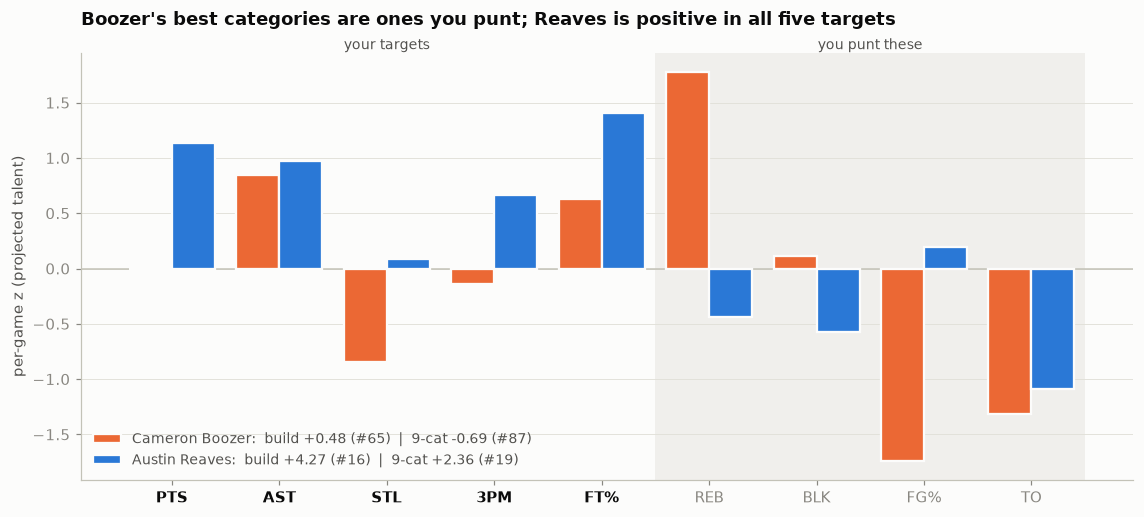

In [3]:
ORDER = ['PTS', 'AST', 'STL', 'FG3M', 'FT', 'REB', 'BLK', 'FG', 'TOV']
x = np.arange(len(ORDER)); w = 0.4
fig, ax = plt.subplots(figsize=(10.5, 4.8))
ax.axvspan(4.5, len(ORDER) - 0.5, color=NEUTRAL, zorder=0, lw=0)
for off, n in ((-w / 2, GIVE), (w / 2, GET)):
    v = ALL.loc[n, ORDER].astype(float)
    ax.bar(x + off, v, w, color=COLOR[n], edgecolor=SURF, linewidth=1.5, zorder=3,
           label=f"{n}:  build {ALL.loc[n, 'zT']:+.2f} (#{ALL.loc[n, 'rankT']})  |  9-cat {ALL.loc[n, 'z9']:+.2f} (#{ALL.loc[n, 'rank9']})")
ax.axhline(0, color=BASE, lw=1, zorder=2)
ax.set_xticks(x, [LAB.get(c, c) for c in ORDER])
for t, c in zip(ax.get_xticklabels(), ORDER):
    if c in TARGETS: t.set_fontweight('bold'); t.set_color(INK)
top = ax.get_ylim()[1]
ax.text(2, top, 'your targets', ha='center', va='bottom', color=INK2, fontsize=9)
ax.text(6.5, top, 'you punt these', ha='center', va='bottom', color=INK2, fontsize=9)
ax.set_ylabel('per-game z (projected talent)'); ax.grid(axis='x', visible=False)
ax.legend(loc='lower left', fontsize=9)
ax.set_title("Boozer's best categories are ones you punt; Reaves is positive in all five targets", pad=18)
plt.tight_layout(); plt.show()

The same thing across the whole league: 9-cat value (roughly what the league pays for a player) against value in your
build. Players above the dotted diagonal are weak in categories you punt, so you get them cheaper than they are worth to
you. Players above the dashed line would rank among your top 10 by build value.

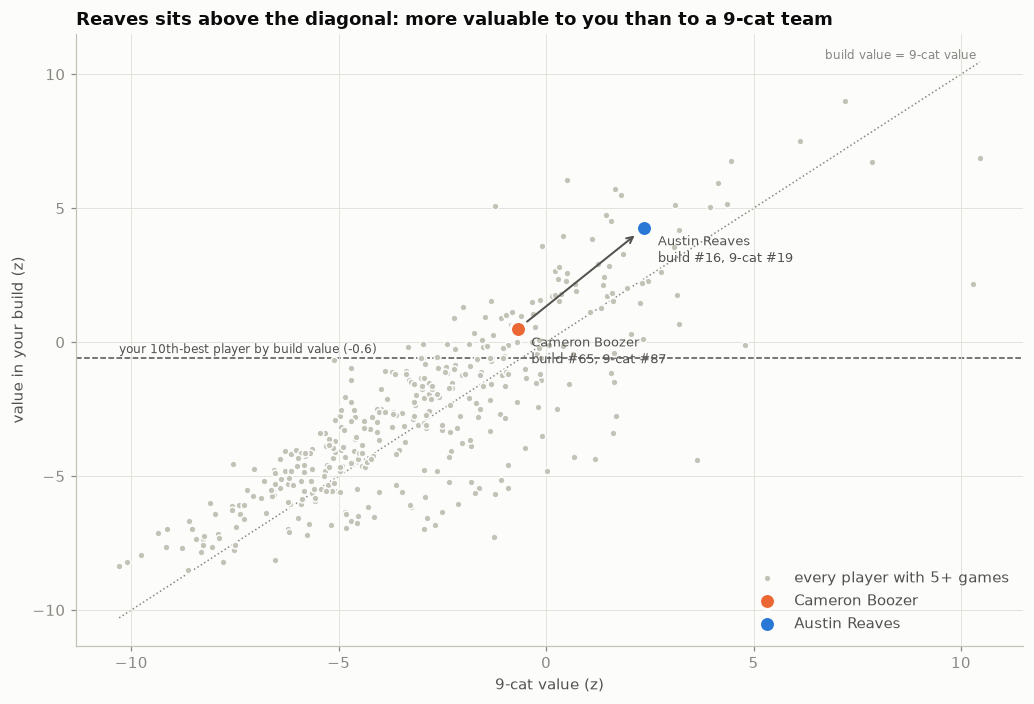

In [4]:
D = ALL
BAR = D[D.team_id == ME].zT.nlargest(10).min()
fig, ax = plt.subplots(figsize=(9.5, 6.5))
ax.scatter(D.z9, D.zT, s=20, color=BASE, edgecolor=SURF, linewidth=1, zorder=2, label='every player with 5+ games')
lo, hi = min(D.z9.min(), D.zT.min()), max(D.z9.max(), D.zT.max())
ax.plot([lo, hi], [lo, hi], color=MUTED, lw=1, ls=':', zorder=1)
ax.text(hi, hi, 'build value = 9-cat value ', ha='right', va='bottom', color=MUTED, fontsize=8, rotation=0)
ax.axhline(BAR, color=INK2, lw=1, ls='--', zorder=1)
ax.text(lo, BAR + 0.2, f'your 10th-best player by build value ({BAR:.1f})', color=INK2, fontsize=8)
pts = {n: (ALL.loc[n, 'z9'], ALL.loc[n, 'zT']) for n in (GIVE, GET)}
ax.annotate('', xy=pts[GET], xytext=pts[GIVE],
            arrowprops=dict(arrowstyle='->', color=INK2, lw=1.3, shrinkA=8, shrinkB=8), zorder=4)
for n in (GIVE, GET):
    ax.scatter(*pts[n], s=110, color=COLOR[n], edgecolor=SURF, linewidth=2, zorder=5, label=n)
    ax.annotate(f'{n}\nbuild #{ALL.loc[n, "rankT"]}, 9-cat #{ALL.loc[n, "rank9"]}', pts[n], xytext=(9, -4),
                textcoords='offset points', fontsize=8.5, color=INK2, va='top')
ax.set_xlabel('9-cat value (z)'); ax.set_ylabel('value in your build (z)')
ax.legend(loc='lower right')
ax.set_title('Reaves sits above the diagonal: more valuable to you than to a 9-cat team')
plt.tight_layout(); plt.show()

## 2. Weekly results: full-league simulation

Every team starts its best legal lineup every day of the real remaining NBA schedule (you by build value, everyone else
by 9-cat value); weekly totals play out the real H2H schedule and the 6-team bracket. Two projections:
**projected talent** (3-season blend) and **this season's form only**. Teams the trade doesn't touch reuse identical
simulated weeks, so the difference between the columns comes from the trade, not from noise.

In [5]:
row = lambda n: R[R.player_name == n].iloc[0]
SIM = {}
for mode in ('talent', 'form'):
    form = mode == 'form'
    base = L.inputs(form_only=form)
    mine = {k: v for k, v in base[ME].items() if k != GIVE}
    mine[GET] = L.player(row(GET), form, True)          # Reaves set in lineups by your build
    part = {k: v for k, v in base[PARTNER].items() if k != GET}
    part[GIVE] = L.player(row(GIVE), form, False)
    T0, S0 = {}, {}
    for t, ps in base.items():
        T0[t], S0[t] = L.sim_team(t, ps, SIMS)
    T1 = dict(T0)
    T1[ME], S1 = L.sim_team(ME, mine, SIMS)
    T1[PARTNER], _ = L.sim_team(PARTNER, part, SIMS)
    SIM[mode] = {'as is': L.season_results(T0, SIMS), 'trade': L.season_results(T1, SIMS), 'starts': (S0[ME], S1)}

rows = []
for mode in SIM:
    for sc in ('as is', 'trade'):
        res = SIM[mode][sc]; my = L.my_summary(res)
        rows.append({'projection': mode, 'scenario': sc, 'exp cats won / week': my['exp_cats_won'],
                     'P(win week)': my['P(win week)'], 'final wins': my['final_wins'], 'P(playoffs)': my['P(playoffs)'],
                     'P(title)': my['P(title)'], f'{L.names[PARTNER]} P(playoffs)': L.summary(res, PARTNER)['P(playoffs)']})
OUT = pd.DataFrame(rows).set_index(['projection', 'scenario'])
display(OUT.round(3))

exp cats won / week  P(win week)  final wins  P(playoffs)  P(title)  Jons of Soe Ingles P(playoffs)
projection scenario                                                                                                     
talent     as is                   4.420        0.482       8.262        0.243     0.007                           0.762
           trade                   4.504        0.513       8.672        0.320     0.018                           0.705
form       as is                   4.641        0.532       8.912        0.416     0.025                           0.938
           trade                   4.679        0.559       9.262        0.495     0.059                           0.928

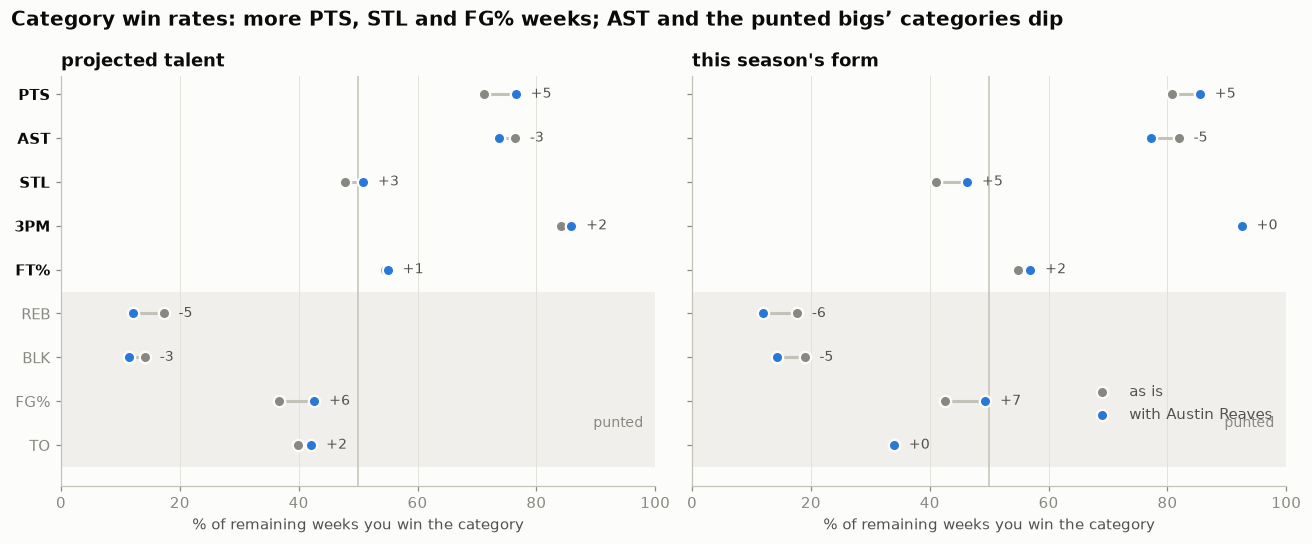

In [6]:
SC = ['PTS', 'AST', 'STL', 'FG3M', 'FT%', 'REB', 'BLK', 'FG%', 'TOV']
y = np.arange(len(SC))[::-1]
fig, axs = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, mode, name in zip(axs, SIM, ('projected talent', "this season's form")):
    a, b = L.my_summary(SIM[mode]['as is']), L.my_summary(SIM[mode]['trade'])
    ax.axhspan(-0.5, 3.5, color=NEUTRAL, zorder=0, lw=0)
    ax.axvline(50, color=BASE, lw=1, zorder=1)
    for yi, c in zip(y, SC):
        va, vb = a[c] * 100, b[c] * 100
        ax.plot([va, vb], [yi, yi], color=BASE, lw=2, zorder=2)
        ax.scatter(va, yi, s=55, color=MUTED, edgecolor=SURF, linewidth=1.5, zorder=3, label='as is' if yi == y[0] else None)
        ax.scatter(vb, yi, s=55, color=BLUE, edgecolor=SURF, linewidth=1.5, zorder=4, label=f'with {GET}' if yi == y[0] else None)
        ax.text(max(va, vb) + 2.5, yi, f'{vb - va:+.0f}', va='center', color=INK2, fontsize=9)
    ax.set_xlim(0, 100); ax.set_xlabel('% of remaining weeks you win the category')
    ax.set_title(name); ax.grid(axis='y', visible=False)
    ax.text(98, 0.5, 'punted', ha='right', va='center', color=MUTED, fontsize=9)
axs[0].set_yticks(y, [LAB.get(c, c) for c in SC])
for t, c in zip(axs[0].get_yticklabels(), SC):
    if c in ('PTS', 'AST', 'STL', 'FG3M', 'FT%'): t.set_fontweight('bold'); t.set_color(INK)
axs[1].legend(loc='lower right', bbox_to_anchor=(1, 0.12))
fig.suptitle('Category win rates: more PTS, STL and FG% weeks; AST and the punted bigs’ categories dip',
             x=0.01, ha='left', fontsize=13, fontweight='bold', color=INK)
plt.tight_layout(); plt.show()

FG% goes **up** even though you punt it: Boozer is your least efficient shooter (FG impact z -1.74). AST dips because
Boozer passes well for a big (+0.85) and Reaves takes starts from your other guards (section 4).

## 3. Season: where you finish

Distribution of your final regular-season seed across the 1,000 simulated seasons. Seeds 1-6 make the playoffs.

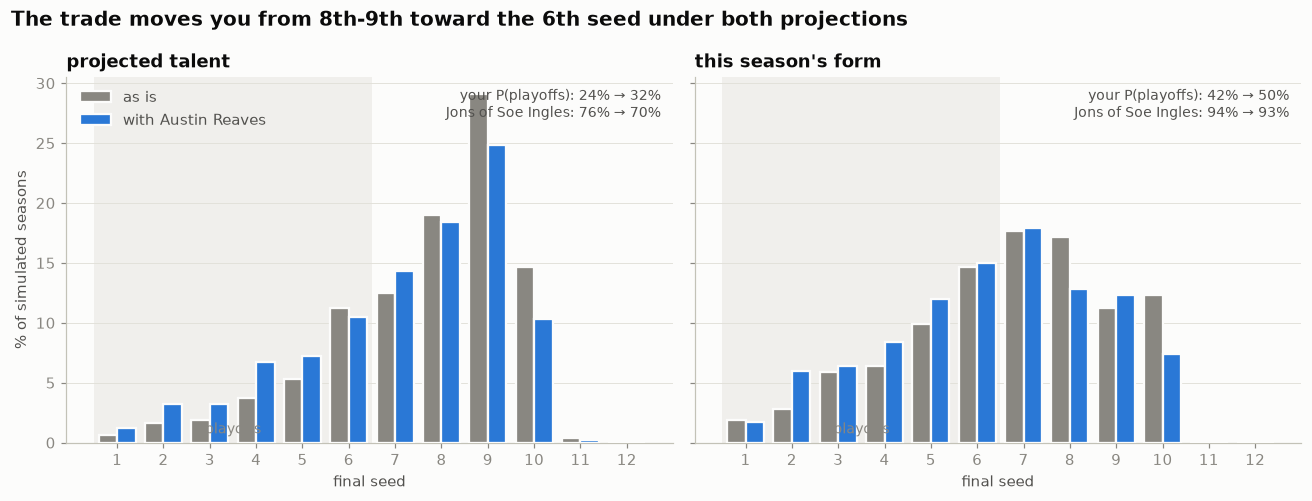

In [7]:
i_me, i_pt = L.teams.index(ME), L.teams.index(PARTNER)
seeds = np.arange(1, len(L.teams) + 1)
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, mode, name in zip(axs, SIM, ('projected talent', "this season's form")):
    ax.axvspan(0.5, L.n_playoff_teams + 0.5, color=NEUTRAL, zorder=0, lw=0)
    for off, sc, col, lab in ((-0.2, 'as is', MUTED, 'as is'), (0.2, 'trade', BLUE, f'with {GET}')):
        s = SIM[mode][sc]['seed'][:, i_me] + 1
        share = np.array([(s == k).mean() for k in seeds]) * 100
        ax.bar(seeds + off, share, 0.4, color=col, edgecolor=SURF, linewidth=1.5, zorder=3, label=lab)
    a, b = (L.summary(SIM[mode][sc], ME)['P(playoffs)'] for sc in ('as is', 'trade'))
    pa, pb = (L.summary(SIM[mode][sc], PARTNER)['P(playoffs)'] for sc in ('as is', 'trade'))
    ax.text(0.98, 0.97, f'your P(playoffs): {a:.0%} → {b:.0%}\n{L.names[PARTNER]}: {pa:.0%} → {pb:.0%}',
            transform=ax.transAxes, ha='right', va='top', color=INK2, fontsize=9)
    ax.text(L.n_playoff_teams / 2 + 0.5, 0.5, 'playoffs', ha='center', va='bottom', color=MUTED, fontsize=9)
    ax.set_xticks(seeds); ax.set_xlabel('final seed'); ax.set_title(name); ax.grid(axis='x', visible=False)
axs[0].set_ylabel('% of simulated seasons'); axs[0].legend(loc='upper left')
fig.suptitle('The trade moves you from 8th-9th toward the 6th seed under both projections',
             x=0.01, ha='left', fontsize=13, fontweight='bold', color=INK)
plt.tight_layout(); plt.show()

## 4. Who loses starts

Your roster has more guards than lineup spots, so Reaves's value isn't all added: some of his starts come from guards
who were already starting. Boozer's PF starts go to Siakam, Kuzma and Marshall. Average starts per week, projected talent.

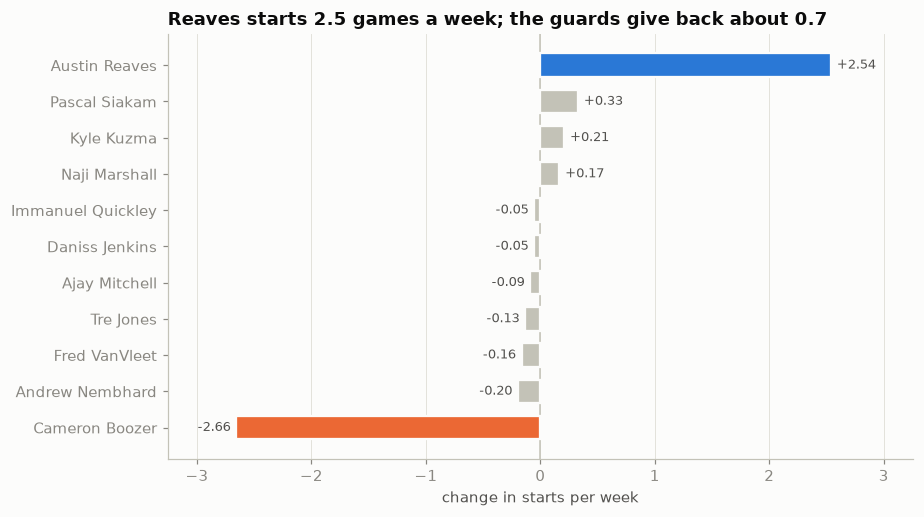

total starts per week: 36.80 as is -> 36.71 with Austin Reaves


In [8]:
s0, s1 = (pd.Series(s) for s in SIM['talent']['starts'])
ch = s1.reindex(s0.index.union(s1.index)).fillna(0) - s0.reindex(s0.index.union(s1.index)).fillna(0)
ch = ch[ch.abs() >= 0.05].sort_values()
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.barh(ch.index, ch, color=[COLOR.get(n, BASE) for n in ch.index], edgecolor=SURF, linewidth=1.5, height=0.65, zorder=3)
for i, (n, v) in enumerate(ch.items()):
    ax.text(v + (0.05 if v > 0 else -0.05), i, f'{v:+.2f}', va='center', ha='left' if v > 0 else 'right', color=INK2, fontsize=8.5)
ax.axvline(0, color=BASE, lw=1)
lim = ch.abs().max() + 0.6; ax.set_xlim(-lim, lim)
ax.set_xlabel('change in starts per week'); ax.grid(axis='y', visible=False)
ax.set_title(f'Reaves starts {ch[GET]:.1f} games a week; the guards give back about {-ch[(ch < 0) & (ch.index != GIVE)].sum():.1f}')
plt.tight_layout(); plt.show()
print(f'total starts per week: {s0.sum():.2f} as is -> {s1.sum():.2f} with {GET}')

## 5. Cost: the next five seasons

Value above replacement (players ranked 157-180) times the expected share of games, with each player's line aged
forward along the league aging curve. This is the price of the trade: Boozer is 19 and improving, Reaves is 28.

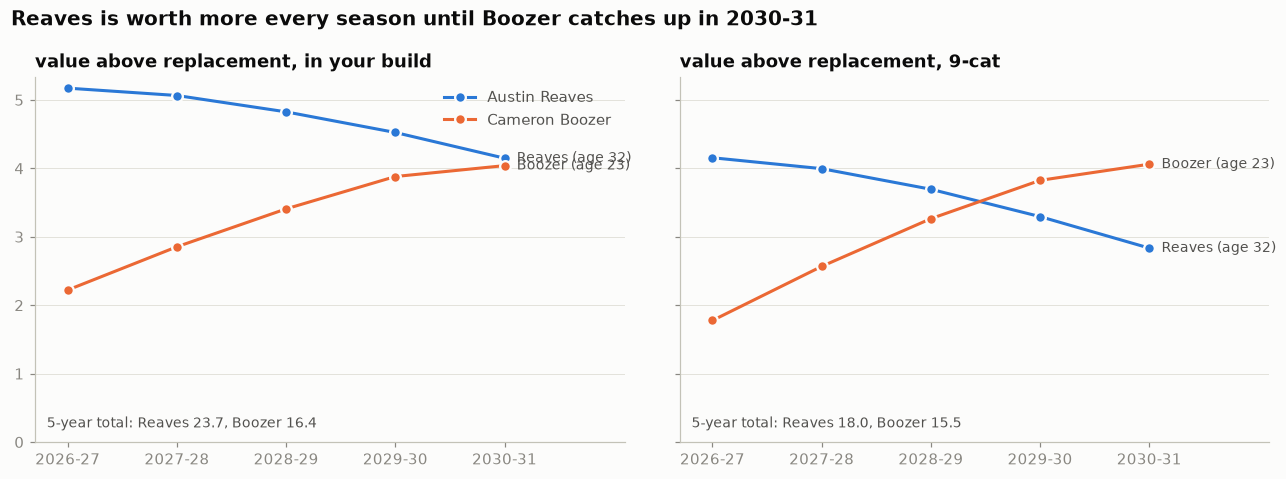

5-year totals, discount 1.0: {'Austin Reaves': {'vT': 23.73, 'v9': 17.97}, 'Cameron Boozer': {'vT': 16.4, 'v9': 15.49}}
5-year totals, discount 0.85: {'Austin Reaves': {'vT': 17.91, 'v9': 13.72}, 'Cameron Boozer': {'vT': 11.6, 'v9': 10.78}}


In [9]:
DY = pd.DataFrame(m.dynasty(PID[GIVE], GIVE, 'GIVE') + m.dynasty(PID[GET], GET, 'GET'))
fig, axs = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, col, name in zip(axs, ('VART', 'VAR9'), ('in your build', '9-cat')):
    for n in (GET, GIVE):
        d = DY[DY.player == n]
        ax.plot(d.season, d[col], color=COLOR[n], lw=2, marker='o', ms=7, mec=SURF, mew=1.5, zorder=3, label=n)
        last = d.iloc[-1]
        ax.annotate(f'{n.split()[-1]} (age {last.age})', (last.season, last[col]), xytext=(8, 0),
                    textcoords='offset points', va='center', fontsize=9, color=INK2)
    tot = DY.groupby('player')[col].sum()
    ax.text(0.02, 0.04, f'5-year total: Reaves {tot[GET]:.1f}, Boozer {tot[GIVE]:.1f}', transform=ax.transAxes,
            color=INK2, fontsize=9)
    ax.set_xticks(DY.season.unique(), [f'{s - 1}-{str(s)[2:]}' for s in DY.season.unique()])
    ax.set_xlim(DY.season.min() - 0.3, DY.season.max() + 1.1); ax.set_title(f'value above replacement, {name}')
    ax.grid(axis='x', visible=False)
axs[0].set_ylim(bottom=0); axs[0].legend(loc='upper right')
fig.suptitle('Reaves is worth more every season until Boozer catches up in 2030-31',
             x=0.01, ha='left', fontsize=13, fontweight='bold', color=INK)
plt.tight_layout(); plt.show()

for disc in (1.0, 0.85):
    v = DY.assign(w=disc ** (DY.season - SEASON)).assign(vT=lambda d: d.VART * d.w, v9=lambda d: d.VAR9 * d.w)
    print(f'5-year totals, discount {disc}:', v.groupby('player')[['vT', 'v9']].sum().round(2).to_dict('index'))

## Verdict

**Take it if winning now matters.** Run the cells above for the current numbers; on the 2026-11-16 data:

- **Fit:** Reaves ranks 9th in the league in your build this season; Boozer ranks 69th. Most of Boozer's 9-cat value
  (REB) is in a category you punt, and his FG% and TO hurt categories other teams care about.
- **Weekly:** about +5 points of PTS win rate, +3 to +5 STL, +6 FG%; AST dips 3 to 5 points.
- **Season:** P(playoffs) 24% → 32% (projected talent) and 42% → 50% (this season's form). The two projections agree,
  unlike the Boozer + Brown offer. Jons of Soe Ingles, the 4th seed you're chasing, loses a little.
- **5 years:** Reaves leads in every season through 2029-30 and in the 5-year totals (build 23.7 vs 16.4).

**What the model leaves out:**

- **After 2031.** Boozer is 24 in 2031 and still rising; every later season is his.
- **Boozer's range.** The aging curve uses the average path. His rookie comparisons run from Haliburton and LaMelo
  to KJ Martin.
- **Market price.** Other dynasty managers likely value a 19-year-old more than this model does, so Reaves might be
  available for less than Boozer.
- **The guard glut.** Section 4: part of Reaves's value is absorbed by benching guards you already have.